# Step 1 — Comparing the class-imbalance strategies (ResNet50, validation fold 0)

This notebook compares the four ResNet50 runs trained with validation fold 0:

| Run folder | Imbalance strategy |
|---|---|
| `r50_none` | none (baseline) |
| `r50_sampler` | `WeightedRandomSampler` |
| `r50_weights` | class-weighted cross-entropy |
| `r50_oversample` | oversampling minority classes |

**Nothing is retrained.** Every run saved its softmax outputs on the test set (`test_probs.npy`).
We rebuild the test labels from `splits/splits.csv` and compute everything from those.

Sections:
1. Setup
2. Load the test labels
3. Load the runs and check them against their saved metrics
4. Results table (overall + per class) → `comparison_table.csv / .tex`
5. Per-class F1 chart → `per_class_f1.png / .pdf`
6. Confusion matrices → `confusion_matrices.png / .pdf`
7. Bootstrap confidence intervals → `bootstrap_ci.csv`, `bootstrap_diff.png / .pdf`
8. McNemar test → `mcnemar.csv`
9. Summary

All outputs go to `reports/figures/comparison/`.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support)

# Project root = the folder that contains Deep_Learning/ (works wherever the notebook is opened from)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Deep_Learning").is_dir())
sys.path.insert(0, str(ROOT))
from Deep_Learning.config import RUNS_DIR, SPLITS_CSV, short_class_names

CLASSES = short_class_names()             # ['CBB', 'CBSD', 'CGM', 'CMD', 'Healthy']
K = len(CLASSES)
OUT = ROOT / "reports" / "figures" / "comparison"
OUT.mkdir(parents=True, exist_ok=True)

VAL_FOLD = 0
BASELINE = "none"
METHODS = ["none", "sampler", "weights", "oversample"]          # fixed row order everywhere
LABEL = {"none": "None (baseline)", "sampler": "Weighted sampler",
         "weights": "Class-weighted loss", "oversample": "Oversampling"}
# One fixed colour per method (validated palette, same family as the imbalance figures)
COLOR = {"none": "#2a78d6", "sampler": "#eb6834", "weights": "#1baf7a", "oversample": "#eda100"}

# Paper style: white background, light grid, no top/right spines, embedded fonts
SURFACE, INK, INK_2, GRID = "#ffffff", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
pd.set_option("display.precision", 4)

def save(fig, stem):
    fig.savefig(OUT / f"{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT / f"{stem}.pdf", bbox_inches="tight")

print("project root:", ROOT)
print("outputs     :", OUT)

project root: /home2/luudh/luudh/MyFile/comp_vision/computer_vision_project
outputs     : /home2/luudh/luudh/MyFile/comp_vision/computer_vision_project/reports/figures/comparison


## 2. Load the test labels

The test set is the rows of `splits.csv` with `split == "test"`. The test DataLoader was not shuffled,
so row *i* here is row *i* of every `test_probs.npy`. Section 3 checks this.

`group_id` marks near-duplicate / same-session images; the bootstrap in section 7 resamples whole groups.

In [2]:
splits = pd.read_csv(SPLITS_CSV)
test = splits[splits.split == "test"].reset_index(drop=True)
y_true = test.label.to_numpy()
groups = test.group_id.to_numpy()

counts = pd.Series(y_true).value_counts().sort_index()
pd.DataFrame({"class": CLASSES, "n_test": counts.values, "%": (100 * counts / counts.sum()).round(1).values})

,class,n_test,%
0,CBB,149,4.8
1,CBSD,306,9.9
2,CGM,345,11.2
3,CMD,1880,61.1
4,Healthy,398,12.9


In [3]:
g = test.group_id.value_counts()
print(f"{len(test)} test images in {len(g)} groups; {(g > 1).sum()} groups have >1 image "
      f"({g[g > 1].sum()} images), largest group = {g.max()}")

3078 test images in 2970 groups; 42 groups have >1 image (150 images), largest group = 19


## 3. Load the runs and check them

For each method we take the run with `val_fold == 0`, read its config and saved metrics, and recompute
accuracy, balanced accuracy and macro-F1 from `argmax(test_probs)`. If anything differs from the
saved `test_metrics.json`, the labels are not aligned with the predictions and we stop.

In [4]:
rows, preds = [], {}
for run_dir in sorted(RUNS_DIR.glob("r50_*")):
    cfg = json.loads((run_dir / "config.json").read_text())
    # only full-data grouped-split ResNet50 runs (step 3 adds random-split and learning-curve runs)
    if (cfg["val_fold"] != VAL_FOLD or cfg["model"] != "resnet50"
            or cfg.get("split", "grouped") != "grouped" or cfg.get("train_frac", 1.0) != 1.0):
        continue
    m = cfg["imbalance"]
    saved = json.loads((run_dir / "test_metrics.json").read_text())
    probs = np.load(run_dir / "test_probs.npy")
    assert probs.shape == (len(y_true), K), f"{run_dir.name}: unexpected shape {probs.shape}"
    assert m not in preds, f"two fold-{VAL_FOLD} runs for method {m}"
    p = probs.argmax(1)
    preds[m] = p
    rows.append({
        "method": m, "run": run_dir.name, "best_epoch": saved["best_epoch"],
        "saved_macro_f1": saved["test_macro_f1"],
        "recomputed_macro_f1": f1_score(y_true, p, average="macro"),
        "saved_acc": saved["test_acc"], "recomputed_acc": accuracy_score(y_true, p),
        "saved_bal_acc": saved["test_balanced_acc"], "recomputed_bal_acc": balanced_accuracy_score(y_true, p),
    })

runs = pd.DataFrame(rows).set_index("method").loc[METHODS]
pairs = [("saved_macro_f1", "recomputed_macro_f1"), ("saved_acc", "recomputed_acc"), ("saved_bal_acc", "recomputed_bal_acc")]
runs["check_ok"] = np.all([np.isclose(runs[a], runs[b], atol=1e-6) for a, b in pairs], axis=0)
assert runs.check_ok.all(), "recomputed metrics do not match test_metrics.json"
runs

,run,best_epoch,saved_macro_f1,recomputed_macro_f1,saved_acc,recomputed_acc,saved_bal_acc,recomputed_bal_acc,check_ok
method,,,,,,,,,
none,r50_none,10,0.7754,0.7754,0.8775,0.8775,0.7748,0.7748,True
sampler,r50_sampler,12,0.7638,0.7638,0.8645,0.8645,0.7763,0.7763,True
weights,r50_weights,6,0.7854,0.7854,0.8762,0.8762,0.7982,0.7982,True
oversample,r50_oversample,12,0.7803,0.7803,0.8804,0.8804,0.7868,0.7868,True


## 4. Results table

Overall metrics plus per-class F1 and recall. Macro-F1 and balanced accuracy weight every class equally,
so they are the metrics that reflect minority-class performance; plain accuracy is dominated by CMD (61%).

In [5]:
def metric_row(p):
    _, rec, f1, _ = precision_recall_fscore_support(y_true, p, labels=range(K), zero_division=0)
    row = {"acc": accuracy_score(y_true, p),
           "balanced_acc": balanced_accuracy_score(y_true, p),
           "macro_f1": f1_score(y_true, p, average="macro")}
    row.update({f"F1 {c}": v for c, v in zip(CLASSES, f1)})
    row.update({f"recall {c}": v for c, v in zip(CLASSES, rec)})
    return row

results = pd.DataFrame({m: metric_row(preds[m]) for m in METHODS}).T
results.index.name = "method"
results.to_csv(OUT / "comparison_table.csv", float_format="%.4f")

# Best value per column in bold
(100 * results).style.format("{:.1f}").highlight_max(axis=0, props="font-weight: bold")

,acc,balanced_acc,macro_f1,F1 CBB,F1 CBSD,F1 CGM,F1 CMD,F1 Healthy,recall CBB,recall CBSD,recall CGM,recall CMD,recall Healthy
method,,,,,,,,,,,,,
none,87.8,77.5,77.5,60.3,78.2,78.6,95.9,74.6,63.8,76.8,76.8,96.4,73.6
sampler,86.5,77.6,76.4,60.1,77.5,77.6,95.3,71.4,65.8,77.1,76.2,93.9,75.1
weights,87.6,79.8,78.5,63.4,81.5,78.3,95.5,73.9,70.5,79.1,78.6,94.4,76.6
oversample,88.0,78.7,78.0,59.6,79.6,79.6,96.2,75.1,66.4,77.1,78.3,96.0,75.6


LaTeX version for the paper (booktabs, values in %, best per column in bold).
The caption warns that most gaps are within the confidence intervals of section 7.

In [6]:
cols = ["acc", "balanced_acc", "macro_f1"] + [f"F1 {c}" for c in CLASSES]
tex_df = (100 * results[cols]).rename(index=LABEL, columns={
    "acc": "Acc.", "balanced_acc": "Bal. acc.", "macro_f1": "Macro-F1", **{f"F1 {c}": c for c in CLASSES}})
tex_df.index.name = None
tex = (tex_df.style.format("{:.1f}").highlight_max(axis=0, props="textbf:--rwrap;")
       .to_latex(hrules=True, position="t", position_float="centering", column_format="l" + "r" * len(cols),
                 label="tab:imbalance-results",
                 caption=("Test-set results (\\%) of ResNet50 under each class-imbalance strategy "
                          "(single run, validation fold 0). The last five columns are per-class F1. "
                          "Best value per column in bold; most differences are within the 95\\% "
                          "bootstrap confidence intervals.")))
(OUT / "comparison_table.tex").write_text(tex)
print(tex)

\begin{table}[t]
\centering
\caption{Test-set results (\%) of ResNet50 under each class-imbalance strategy (single run, validation fold 0). The last five columns are per-class F1. Best value per column in bold; most differences are within the 95\% bootstrap confidence intervals.}
\label{tab:imbalance-results}
\begin{tabular}{lrrrrrrrr}
\toprule
 & Acc. & Bal. acc. & Macro-F1 & CBB & CBSD & CGM & CMD & Healthy \\
\midrule
None (baseline) & 87.8 & 77.5 & 77.5 & 60.3 & 78.2 & 78.6 & 95.9 & 74.6 \\
Weighted sampler & 86.5 & 77.6 & 76.4 & 60.1 & 77.5 & 77.6 & 95.3 & 71.4 \\
Class-weighted loss & 87.6 & \textbf{79.8} & \textbf{78.5} & \textbf{63.4} & \textbf{81.5} & 78.3 & 95.5 & 73.9 \\
Oversampling & \textbf{88.0} & 78.7 & 78.0 & 59.6 & 79.6 & \textbf{79.6} & \textbf{96.2} & \textbf{75.1} \\
\bottomrule
\end{tabular}
\end{table}



## 5. Per-class F1 chart

Where do the methods differ? The gaps are largest on the small classes (CBB, CBSD, Healthy);
CMD is near 96% for every method.

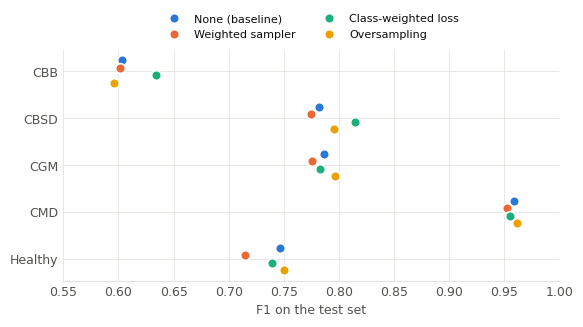

In [7]:
# Dot plot: one row per class, one dot per method (dots need no zero baseline, so small gaps stay visible)
fig, ax = plt.subplots(figsize=(6.4, 3.0))
offsets = np.linspace(0.24, -0.24, len(METHODS))          # small vertical shift so dots don't overlap
y = np.arange(K)[::-1]
for yi in y:
    ax.axhline(yi, color=GRID, lw=0.6, zorder=0)
for off, m in zip(offsets, METHODS):
    vals = results.loc[m, [f"F1 {c}" for c in CLASSES]].to_numpy()
    ax.plot(vals, y + off, "o", ms=7, color=COLOR[m], mec=SURFACE, mew=1.2, label=LABEL[m], zorder=3)
ax.set_yticks(y, CLASSES)
ax.set_xlabel("F1 on the test set")
ax.set_xlim(0.55, 1.0)
ax.xaxis.grid(True, color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.spines["left"].set_visible(False)
ax.legend(ncol=2, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8)
save(fig, "per_class_f1")
plt.show()

## 6. Confusion matrices

Rows = true class, columns = predicted class, row-normalised (each row sums to 100%); counts in brackets.

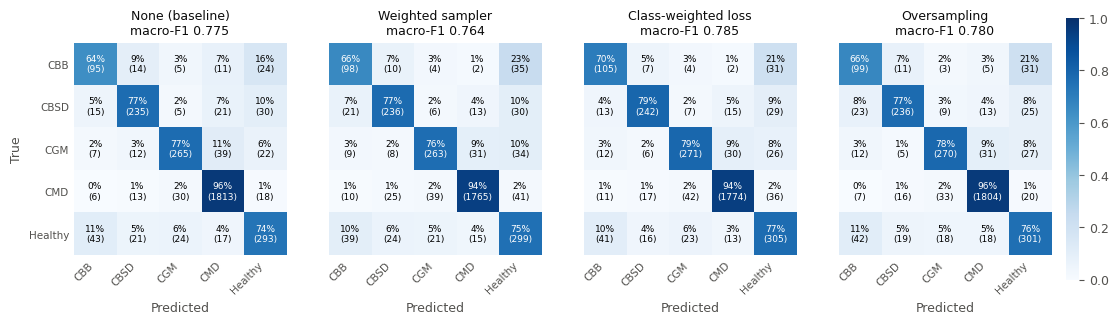

In [8]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(13, 3.4))
for ax, m in zip(axes, METHODS):
    cm = confusion_matrix(y_true, preds[m], labels=range(K))
    cmn = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0%}\n({cm[i, j]})", ha="center", va="center", fontsize=6.5,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(f"{LABEL[m]}\nmacro-F1 {results.loc[m, 'macro_f1']:.3f}", fontsize=9)
    ax.set_xticks(range(K), CLASSES, rotation=45, ha="right", fontsize=7.5)
    ax.set_yticks(range(K), CLASSES if ax is axes[0] else [], fontsize=7.5)
    ax.set_xlabel("Predicted")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_ylabel("True")
cbar = fig.colorbar(im, ax=list(axes), fraction=0.015, pad=0.015)
cbar.outline.set_visible(False)
save(fig, "confusion_matrices")
plt.show()

In [9]:
# The most common mistake per true class (excluding the diagonal), for each method
rows = []
for m in METHODS:
    cm = confusion_matrix(y_true, preds[m], labels=range(K)).astype(float)
    cmn = cm / cm.sum(1, keepdims=True)
    np.fill_diagonal(cmn, 0)
    for i, c in enumerate(CLASSES):
        j = cmn[i].argmax()
        rows.append({"method": m, "true": c, "most often predicted as": CLASSES[j], "share": cmn[i, j]})
top_errors = pd.DataFrame(rows).pivot(index="true", columns="method", values=["most often predicted as", "share"])
top_errors

most often predicted as                                share  \
method                     none oversample  sampler  weights    none   
true                                                                   
CBB                     Healthy    Healthy  Healthy  Healthy  0.1611   
CBSD                    Healthy    Healthy  Healthy  Healthy   0.098   
CGM                         CMD        CMD  Healthy      CMD   0.113   
CMD                         CGM        CGM  Healthy      CGM   0.016   
Healthy                     CBB        CBB      CBB      CBB   0.108   

                                    
method  oversample sampler weights  
true                                
CBB         0.2081  0.2349  0.2081  
CBSD        0.0817   0.098  0.0948  
CGM         0.0899  0.0986   0.087  
CMD         0.0176  0.0218  0.0223  
Healthy     0.1055   0.098   0.103

## 7. Bootstrap confidence intervals

**Question:** if we had drawn a different test set of the same size, how much would each score move,
and is the gap between a method and the baseline bigger than that?

**How:** draw 10,000 resamples of the test set with replacement and recompute every metric on each.
- *Paired:* in each draw the same images are used for all four methods, so the difference vs. the
  baseline is measured on identical images.
- *Grouped:* we resample `group_id`s, not single images, so near-duplicates stay together.

The 95% interval is the 2.5th–97.5th percentile of the 10,000 values. A difference is
"significant" here when its interval does not contain 0.

*Note:* this captures test-set noise only, not training noise (different seeds / folds). Step 2 covers that.

In [10]:
N_BOOT, SEED = 10_000, 0

def metrics_from_cm(cm):
    # (acc, balanced acc, macro-F1) from a K x K confusion matrix; same definitions as sklearn
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(1), cm.sum(0)
    recall = np.divide(tp, support, out=np.zeros(K), where=support > 0)
    f1 = np.divide(2 * tp, support + predicted, out=np.zeros(K), where=(support + predicted) > 0)
    return tp.sum() / cm.sum(), recall[support > 0].mean(), f1[(support + predicted) > 0].mean()

# Indices of the images in each group
_, group_idx = np.unique(groups, return_inverse=True)
members = pd.Series(np.arange(len(groups))).groupby(group_idx).apply(np.array).tolist()
codes = {m: y_true * K + preds[m] for m in METHODS}       # encodes (true, pred) as one integer

rng = np.random.default_rng(SEED)
boot = {m: np.empty((N_BOOT, 3)) for m in METHODS}
for b in range(N_BOOT):
    idx = np.concatenate([members[g] for g in rng.integers(0, len(members), len(members))])
    for m in METHODS:
        cm = np.bincount(codes[m][idx], minlength=K * K).reshape(K, K)
        boot[m][b] = metrics_from_cm(cm)
print("done:", N_BOOT, "resamples of", len(members), "groups")

done: 10000 resamples of 2970 groups


In [11]:
METRICS = ["acc", "balanced_acc", "macro_f1"]
rows = []
for m in METHODS:
    for j, metric in enumerate(METRICS):
        row = {"method": m, "metric": metric, "value": results.loc[m, metric],
               "ci_low": np.percentile(boot[m][:, j], 2.5), "ci_high": np.percentile(boot[m][:, j], 97.5)}
        if m != BASELINE:
            d = boot[m][:, j] - boot[BASELINE][:, j]
            row.update({"diff_vs_baseline": results.loc[m, metric] - results.loc[BASELINE, metric],
                        "diff_ci_low": np.percentile(d, 2.5), "diff_ci_high": np.percentile(d, 97.5)})
            row["significant"] = bool(row["diff_ci_low"] > 0 or row["diff_ci_high"] < 0)
        rows.append(row)
ci = pd.DataFrame(rows)
ci.to_csv(OUT / "bootstrap_ci.csv", index=False, float_format="%.4f")
ci.set_index(["metric", "method"]).sort_index(level=0, sort_remaining=False)

value  ci_low  ci_high  diff_vs_baseline  \
metric       method                                                  
acc          none        0.8775  0.8657   0.8891               NaN   
             sampler     0.8645  0.8522   0.8768           -0.0130   
             weights     0.8762  0.8642   0.8880           -0.0013   
             oversample  0.8804  0.8686   0.8921            0.0029   
balanced_acc none        0.7748  0.7532   0.7962               NaN   
             sampler     0.7763  0.7539   0.7983            0.0014   
             weights     0.7982  0.7763   0.8190            0.0234   
             oversample  0.7868  0.7644   0.8083            0.0120   
macro_f1     none        0.7754  0.7541   0.7955               NaN   
             sampler     0.7638  0.7423   0.7844           -0.0116   
             weights     0.7854  0.7645   0.8050            0.0100   
             oversample  0.7803  0.7591   0.8001            0.0048   

                         diff_ci_low  diff_ci_high significant  
metric       method                                             
acc          none                NaN           NaN         NaN  
             sampler         -0.0216       -0.0042        True  
             weights         -0.0094        0.0068       False  
             oversample      -0.0052        0.0111       False  
balanced_acc none                NaN           NaN         NaN  
             sampler         -0.0158        0.0190       False  
             weights          0.0067        0.0399        True  
             oversample      -0.0058        0.0300       False  
macro_f1     none                NaN           NaN         NaN  
             sampler         -0.0278        0.0048       False  
             weights         -0.0050        0.0254       False  
             oversample      -0.0111        0.0211       False

The same differences as a chart: each dot is a method's difference from the baseline (in percentage
points), the bar is its 95% interval. Bars that cross the dashed zero line are **not** significant.

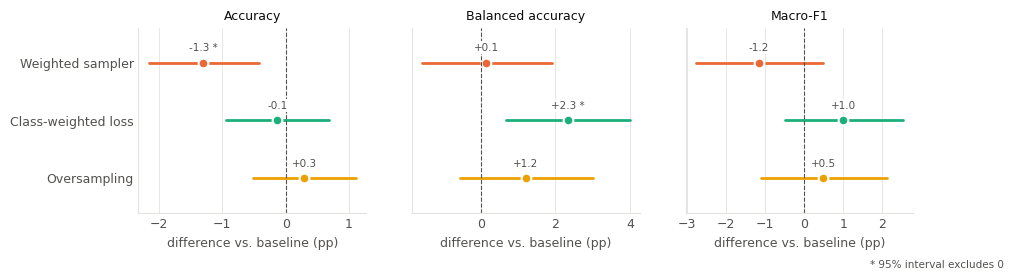

In [12]:
NAMES = {"acc": "Accuracy", "balanced_acc": "Balanced accuracy", "macro_f1": "Macro-F1"}
others = [m for m in METHODS if m != BASELINE]
fig, axes = plt.subplots(1, 3, figsize=(10, 2.4), sharey=True)
for ax, metric in zip(axes, METRICS):
    d = ci[(ci.metric == metric) & (ci.method != BASELINE)].set_index("method").loc[others]
    y = np.arange(len(others))[::-1]
    for yi, m in zip(y, others):
        r = d.loc[m]
        ax.plot([100 * r.diff_ci_low, 100 * r.diff_ci_high], [yi, yi], color=COLOR[m], lw=2,
                solid_capstyle="round")
        ax.plot(100 * r.diff_vs_baseline, yi, "o", color=COLOR[m], ms=7, mec=SURFACE, mew=1.5)
        ax.annotate(f"{100 * r.diff_vs_baseline:+.1f}" + (" *" if r.significant else ""),
                    (100 * r.diff_vs_baseline, yi), xytext=(0, 7), textcoords="offset points",
                    ha="center", va="bottom", fontsize=7.5, color=INK_2,
                    bbox=dict(boxstyle="square,pad=0.15", fc=SURFACE, ec="none"), zorder=5)
    ax.axvline(0, color=INK_2, lw=0.8, ls="--")
    ax.set_title(NAMES[metric], fontsize=9)
    ax.set_xlabel("difference vs. baseline (pp)")
    ax.xaxis.grid(True, color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
axes[0].set_yticks(np.arange(len(others))[::-1], [LABEL[m] for m in others])
axes[0].set_ylim(-0.6, len(others) - 0.4)
fig.text(0.99, -0.12, "* 95% interval excludes 0", ha="right", fontsize=7.5, color=INK_2)
save(fig, "bootstrap_diff")
plt.show()

## 8. McNemar test (paired, accuracy only)

For each method vs. the baseline, count the images that **only one** of the two models gets right:
- `only_baseline_correct` (b) and `only_method_correct` (c).

If the two models were equally accurate, b and c would be about equal. The exact McNemar test is a
binomial test of c out of b + c at p = 0.5. Images both get right or both get wrong say nothing about
the difference, so they are ignored.

Three methods are tested against one baseline, so p-values are Holm-corrected for 3 comparisons.
**This tests accuracy, which is dominated by CMD**, not macro-F1.

In [13]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); adj = np.empty_like(p); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

base_ok = preds[BASELINE] == y_true
rows = []
for m in others:
    ok = preds[m] == y_true
    b, c = int((base_ok & ~ok).sum()), int((~base_ok & ok).sum())
    rows.append({"method": m, "both_correct": int((base_ok & ok).sum()), "both_wrong": int((~base_ok & ~ok).sum()),
                 "only_baseline_correct": b, "only_method_correct": c,
                 "p_value": binomtest(c, b + c, 0.5).pvalue})
mcnemar = pd.DataFrame(rows).set_index("method")
mcnemar["p_holm"] = holm(mcnemar.p_value)
mcnemar["significant (p_holm < 0.05)"] = mcnemar.p_holm < 0.05
mcnemar.to_csv(OUT / "mcnemar.csv", float_format="%.4g")
mcnemar

,both_correct,both_wrong,only_baseline_correct,only_method_correct,p_value,p_holm,significant (p_holm < 0.05)
method,,,,,,,
sampler,2583,299,118,78,0.0052,0.0156,True
weights,2621,301,80,76,0.8103,1.0000,False
oversample,2623,290,78,87,0.5335,1.0000,False


## 9. Summary

Generated from the tables above, so it stays correct if the runs change.

In [14]:
for metric in METRICS:
    print(f"\n{NAMES[metric]}:")
    for m in others:
        r = ci[(ci.metric == metric) & (ci.method == m)].iloc[0]
        verdict = "SIGNIFICANT" if r.significant else "not significant"
        print(f"  {LABEL[m]:<20} {100 * r.diff_vs_baseline:+5.1f} pp  "
              f"[{100 * r.diff_ci_low:+.1f}, {100 * r.diff_ci_high:+.1f}]  {verdict}")
print("\nMcNemar (accuracy), Holm-corrected:")
for m, r in mcnemar.iterrows():
    print(f"  {LABEL[m]:<20} b={r.only_baseline_correct:<4} c={r.only_method_correct:<4} p_holm={r.p_holm:.3g}")
print("\nFiles written to", OUT)
for f in sorted(OUT.iterdir()):
    print("  ", f.name)


Accuracy:
  Weighted sampler      -1.3 pp  [-2.2, -0.4]  SIGNIFICANT
  Class-weighted loss   -0.1 pp  [-0.9, +0.7]  not significant
  Oversampling          +0.3 pp  [-0.5, +1.1]  not significant

Balanced accuracy:
  Weighted sampler      +0.1 pp  [-1.6, +1.9]  not significant
  Class-weighted loss   +2.3 pp  [+0.7, +4.0]  SIGNIFICANT
  Oversampling          +1.2 pp  [-0.6, +3.0]  not significant

Macro-F1:
  Weighted sampler      -1.2 pp  [-2.8, +0.5]  not significant
  Class-weighted loss   +1.0 pp  [-0.5, +2.5]  not significant
  Oversampling          +0.5 pp  [-1.1, +2.1]  not significant

McNemar (accuracy), Holm-corrected:
  Weighted sampler     b=118  c=78   p_holm=0.0156
  Class-weighted loss  b=80   c=76   p_holm=1
  Oversampling         b=78   c=87   p_holm=1

Files written to /home2/luudh/luudh/MyFile/comp_vision/computer_vision_project/reports/figures/comparison
   bootstrap_ci.csv
   bootstrap_diff.pdf
   bootstrap_diff.png
   comparison_table.csv
   comparison_table.tex
